# 03 — Pré-processamento, Engenharia de *Features* e Estrutura de Painel

**Objetivo.** Transformar a amostra analítica validada no notebook 02 no painel de modelagem: uma
linha por **jogador–temporada** $T$, com o vetor explicativo $\mathbf{X}_{i,T}$ medido até a
data-âncora de $T$ (30 de junho do ano de término da temporada) e as variáveis-alvo em $T+1$ e
$T+2$.

**Entrada:** `data/raw/football_raw_dataset.parquet` e as tabelas do Transfermarkt em
`data/interim/` (histórico de valores, perfis e transferências).
**Saídas:**
- `data/processed/train_test_lags.parquet`: painel de modelagem com dicionário de dados.
- `data/processed/feature_sets.json`: listas de features, alvos e dobras para o notebook 04.
- `reports/figures/03_preprocessing/` e `reports/tables/03_preprocessing/`.

**O que este notebook faz e o que fica para o 04.** Aqui se constroem as variáveis e a estrutura
temporal. A **imputação** de ausentes e a **padronização** (RobustScaler/StandardScaler por
categoria) dependem de estatísticas do conjunto de treino. Para não haver vazamento entre dobras,
as duas são ajustadas dentro de cada dobra da janela expandida, no notebook 04 (especificação,
§6.6, passos 3 e 4).

**Princípio de não antecipação.** Toda *feature* usa apenas informação disponível na data-âncora
de $T$. As poucas variáveis cuja construção depende de eventos posteriores (como o modo pelo qual
o contrato em $T$ foi reconstruído) ficam marcadas como **auditoria** e são excluídas do vetor
explicativo.

## 0. Configuração

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

from football_analytics import contracts as ct
from football_analytics import feature_catalog as fc
from football_analytics import features as ft
from football_analytics import plotting as pl
from football_analytics import sample as sp
from football_analytics.config import Season, default_config
from football_analytics.io import load_table, save_table
from football_analytics.logging_utils import setup_logging
from football_analytics.validation import expanding_window_folds
from football_analytics.valuation import attach_values

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

cfg = default_config()
paths = cfg.paths
logger = setup_logging(paths.logs / "03_preprocessing.log")
pl.setup_style()
FIG = pl.FigureRegistry(
    paths.figures("03_preprocessing"),
    source="Elaboração própria com dados de FBref, Understat, Sofascore e Transfermarkt (2026)",
)
TABLES = paths.tables("03_preprocessing")
TABLES.mkdir(parents=True, exist_ok=True)
paths.processed.mkdir(parents=True, exist_ok=True)


def save_csv(df: pd.DataFrame, name: str, index: bool = True) -> None:
    df.to_csv(TABLES / f"{name}.csv", index=index, encoding="utf-8-sig", float_format="%.4f")


SEASONS = list(cfg.feature_seasons)
# Alvos de T+1 de 2024/25 (teste pré-registrado) ficam ocultos em todos os diagnósticos deste notebook.
HOLDOUT_T1 = {1: cfg.holdout_seasons[1]}
SEASON_LABELS = [sp.season_label(s) for s in SEASONS]
POS = list(sp.POSITIONS)
BANDS = list(sp.AGE_BAND_LABELS)

In [2]:
raw = load_table(paths.final_dataset)
mv = load_table(paths.interim / "tm_market_values_long.parquet")
profiles = load_table(paths.interim / "tm_profiles.parquet")
transfers = load_table(paths.interim / "tm_transfers_long.parquet")
fetch_status = load_table(paths.interim / "tm_fetch_status.parquet")  # quem teve o histórico coletado

analytic = sp.build_analytic_sample(raw)  # mesmas regras do notebook 02
sample_keys = pd.MultiIndex.from_frame(analytic.sample[sp.KEY])
print(f"Amostra analítica (notebook 02): {len(sample_keys):,} jogador–temporada")

Amostra analítica (notebook 02): 13,748 jogador–temporada


## 1. Painel jogador–temporada com estatísticas agregadas

O dataset bruto tem uma linha por **jogador–clube–temporada**. Para atletas transferidos dentro
das Big Five na mesma temporada, as contagens das três fontes de desempenho são somadas, e as
taxas são recalculadas a partir das somas. No caso das taxas publicadas sem denominador (nota e
percentuais de duelos do Sofascore), usa-se a média ponderada pelos minutos.

Os atributos do Transfermarkt e o clube de referência vêm do clube com mais minutos. Uma mesma
linha do Understat ou do Sofascore pode estar casada com as duas linhas de clube do FBref (quando a
fonte publica o total da temporada). Ela é contada uma única vez, pela deduplicação do id da fonte.

O painel é construído para **todas** as temporadas coletadas, inclusive 2018/19, porque as
defasagens de 2019/20 dependem dela. Depois é restrito à amostra analítica.

In [3]:
ps = sp.add_value_targets(sp.add_demographics(ft.aggregate_player_season(raw)))
perf_all = ft.performance_features(ps)
lags_all = ft.performance_lags(ps[["season", "fbref_player_id"]].join(perf_all))

in_sample = pd.MultiIndex.from_frame(ps[sp.KEY]).isin(sample_keys)
base = ps[in_sample].copy()
assert len(base) == len(sample_keys), "o painel agregado não reproduz a amostra do notebook 02"
diag = sp.mask_holdout_targets(base, HOLDOUT_T1)  # cópia sem os alvos de T+1 de 2024/25
print(f"Painel agregado: {len(ps):,} jogador–temporada (todas as temporadas); "
      f"{len(base):,} na amostra analítica")
print(f"Atletas com mais de um clube das Big Five em T: {(base['n_club_rows'] > 1).sum():,}")

Painel agregado: 21,376 jogador–temporada (todas as temporadas); 13,748 na amostra analítica
Atletas com mais de um clube das Big Five em T: 834


## 2. Vetor demográfico

- **Idade e idade²**, em anos completos na data-âncora. O termo quadrático captura a concavidade
  do ciclo de vida observada na Figura 12 do notebook 02.
- **Altura** e **pé preferencial**: *dummies* para canhoto e ambidestro, com destro como
  referência.
- **Nacionalidade:**
  - *dummies* de confederação da primeira nacionalidade (UEFA, CONMEBOL, CAF e AFC/CONCACAF,
    agrupamento da especificação; a OFC entra no último grupo, pelo número ínfimo de atletas);
  - **passaporte comunitário** (nacionalidade de um país da UE; britânicos contam só em 2019/20,
    pelo fim do período de transição do Brexit em 31/12/2020);
  - **atleta nacional** (tem a nacionalidade do país da liga).

In [4]:
demo = ft.demographic_features(base)
conf_share = (demo["confederation"].value_counts(normalize=True) * 100).rename("% da amostra")
flags = demo[["has_eu_passport", "is_domestic", "is_left_footed", "is_two_footed"]].mean() * 100
save_csv(pd.concat([conf_share, flags.rename("% da amostra")]).to_frame(), "tab01_perfil_demografico")
display(conf_share.round(1).to_frame(), flags.round(1).rename("% da amostra").to_frame())
print(f"Altura ausente: {demo['height_cm'].isna().mean() * 100:.1f}%  |  "
      f"nacionalidade ausente: {demo['confederation'].isna().mean() * 100:.1f}%")

,% da amostra
confederation,
UEFA,70.900
CAF,15.000
CONMEBOL,9.600
CONCACAF,2.900
AFC,1.500
OFC,0.200


,% da amostra
has_eu_passport,76.900
is_domestic,54.200
is_left_footed,26.800
is_two_footed,2.900


Altura ausente: 0.5%  |  nacionalidade ausente: 0.0%


## 3. Contrato vigente em $T$

O Transfermarkt publica apenas o **contrato atual** (coletado em out/2026). O contrato em vigor
em 30 de junho de $T$ é reconstruído cruzando o perfil atual com o histórico completo de
transferências do atleta (`football_analytics.contracts`):

| Situação após $T$ | Regra | Status |
|---|---|---|
| Continua no clube de $T$ e o contrato atual foi assinado (chegada ou última renovação) até $T$ | término = contrato atual | **observado** |
| Deixou o clube de $T$ em transferência livre, ou ficou sem clube/aposentou-se | término = data da saída (30/jun para saídas de verão) | **observado** |
| Renovou depois de $T$, foi vendido depois de $T$, estava emprestado em $T$, ou o contrato atual excede 5 anos desde a assinatura (renovação não registrada) | mediana dos anos restantes observados no mesmo estrato *tempo de casa × faixa etária* | **estimado** |

O limite de cinco anos vem do art. 18.2 do Regulamento de Transferências da FIFA. A partir do tempo
restante define-se o **status Bosman**: último ano de contrato, com no máximo um ano restante em
30 de junho de $T$.

**Cuidado com vazamento.** Toda observação do contrato em $T$ depende de um evento posterior a
$T$: a saída livre, a venda ou a permanência no clube até hoje. Saber *por que* o contrato não é
observado (o atleta foi vendido ou renovou depois de $T$) é informação do futuro, e ela se
correlaciona com a valorização. Por isso o método e a *flag* de estimativa são colunas de
**auditoria**. A última tabela desta seção mostra um efeito mais sutil: a própria mistura de
valores observados e estimados antecipa o desfecho. As duas variáveis contratuais reconstruídas
(`contract_years_remaining_T`, `bosman_T`) são, por isso, classificadas como **de sensibilidade**
(`lookahead`): ficam no painel, mas fora do vetor explicativo principal. O notebook 04 deve
usá-las apenas num modelo de robustez, explicitamente rotulado. O tempo de casa em $T$ e o
empréstimo em $T$ dependem só do passado e entram como *features*.

In [5]:
fetched = set(fetch_status.loc[fetch_status["has_transfers"], "tm_player_id"].astype(int))
contracts = ct.contracts_at_anchor(base, transfers, profiles, fetched)
print("Histórico de transferências não coletado (bloqueio do TM), por temporada:",
      (contracts["contract_method"] == "not_collected").groupby(base["season"]).mean().mul(100).round(1).to_dict())
method_share = (pd.crosstab(base["season"], contracts["contract_method"], normalize="index") * 100)
method_share.index = SEASON_LABELS
method_total = contracts["contract_method"].value_counts(normalize=True).mul(100).rename("% total")
save_csv(method_share.T.assign(total=method_total), "tab02_metodo_contrato")
display(method_share.T.assign(total=method_total).round(1).rename(index=ct.METHOD_LABELS))

backtest = ct.estimator_backtest(contracts, base)
save_csv(backtest.to_frame("valor"), "tab03_validacao_estimativa_contrato")
display(backtest.round(3).to_frame("valor"))

Histórico de transferências não coletado (bloqueio do TM), por temporada: {'1819': 0.6, '1920': 0.7, '2021': 0.7, '2122': 0.6, '2223': 0.6, '2324': 0.7, '2425': 19.7}


,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25,total
contract_method,,,,,,,,
Observado: contrato atual já vigente em T,0.000,0.000,0.000,0.100,1.900,10.500,21.300,4.800
Estimado: renovação posterior a T,2.200,3.400,3.800,5.800,9.500,11.500,9.600,6.600
Observado: saída livre após T,48.600,48.700,52.300,46.600,39.300,31.500,19.700,40.900
Estimado: sem dado contratual,0.300,0.400,0.300,0.500,0.900,1.300,1.100,0.700
Sem coleta: histórico de transferências não coletado (bloqueio do Transfermarkt),0.600,0.700,0.700,0.600,0.600,0.700,19.700,3.400
Estimado: emprestado em T,0.900,10.700,0.900,0.900,0.700,0.800,0.500,2.200
Estimado: venda após T,47.300,35.900,41.200,44.300,45.400,41.400,24.800,40.000
Estimado: renovação não registrada,0.200,0.200,0.700,1.100,1.900,2.300,3.200,1.400


,valor
n_observados,"6,291.000"
MAE_estrato_anos,1.012
MAE_mediana_global_anos,1.168
acuracia_bosman,0.613
taxa_bosman_observada,0.439


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/03_preprocessing/fig01_origem_contrato.png


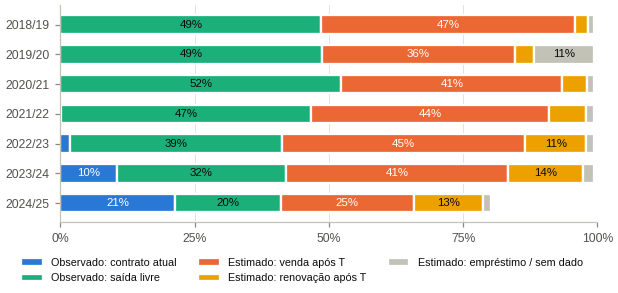

In [6]:
groups = {
    "Observado: contrato atual": ["current_contract"],
    "Observado: saída livre": ["free_exit"],
    "Estimado: venda após T": ["transfer_exit"],
    "Estimado: renovação após T": ["extension_after_T", "unrecorded_extension"],
    "Estimado: empréstimo / sem dado": ["on_loan", "no_contract_data"],
}
colors = [pl.BLUE, pl.AQUA, pl.ORANGE, "#eda100", pl.NEUTRAL]
grp = pd.DataFrame({g: method_share.reindex(columns=m, fill_value=0).sum(axis=1) for g, m in groups.items()})

fig, ax = plt.subplots(figsize=pl.figsize(6.5))
left = np.zeros(len(grp))
for (name, col), color in zip(grp.items(), colors):
    ax.barh(range(len(grp)), col, left=left, color=color, height=0.62, label=name, edgecolor=pl.SURFACE, linewidth=1.5)
    for i, (l, v) in enumerate(zip(left, col)):
        if v >= 7:
            ax.text(l + v / 2, i, pl.br_pct(v, 0), ha="center", va="center", fontsize=7.5,
                    color=pl.INK if color in (pl.NEUTRAL, "#eda100", pl.AQUA) else pl.SURFACE)
    left += col.to_numpy()
ax.set_yticks(range(len(grp)), grp.index)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100])
ax.xaxis.set_major_formatter(pl.pct_formatter(0))
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=3, fontsize=7)
FIG.save(fig, "fig01_origem_contrato",
         "Origem da informação sobre o contrato vigente em T, por temporada de referência",
         note="Observado: término conhecido sem estimativa. Estimado: mediana do estrato tempo de casa × faixa etária.")
plt.show()

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/03_preprocessing/fig02_contrato_bosman.png


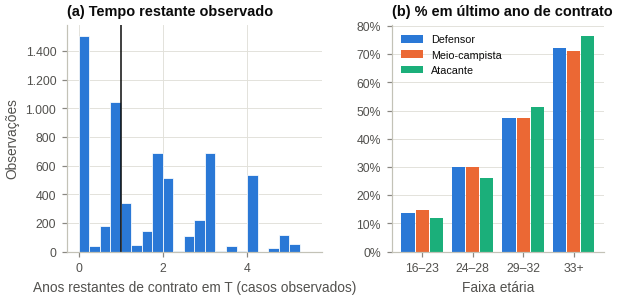

In [7]:
bos = (base.assign(bosman=contracts["bosman_T"])
       .groupby(["age_band", "position_group"], observed=True)["bosman"].mean().unstack().reindex(columns=POS) * 100)
save_csv(bos, "tab04_bosman_por_categoria")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=pl.figsize(6.8), gridspec_kw={"wspace": 0.3, "width_ratios": [1.2, 1]})
obs_years = contracts.loc[~contracts["contract_is_estimated"], "contract_years_remaining_T"]
ax1.hist(obs_years, bins=np.arange(0, 5.75, 0.25), color=pl.BLUE, edgecolor=pl.SURFACE, linewidth=0.5)
ax1.axvline(1, color=pl.INK, linewidth=1)
ax1.set_xlabel("Anos restantes de contrato em T (casos observados)")
ax1.set_ylabel("Observações")
ax1.yaxis.set_major_formatter(pl.br_formatter(0))
ax1.set_title("(a) Tempo restante observado")
width = 0.26
for p, pos in enumerate(POS):
    ax2.bar(np.arange(len(BANDS)) + (p - 1) * (width + 0.02), bos[pos].to_numpy(), width=width,
            color=pl.POSITION_COLORS[pos], label=sp.POSITION_LABELS[pos])
ax2.set_xticks(range(len(BANDS)), BANDS)
ax2.yaxis.set_major_formatter(pl.pct_formatter(0))
ax2.set_xlabel("Faixa etária")
ax2.set_title("(b) % em último ano de contrato")
ax2.grid(axis="x", visible=False)
ax2.legend(loc="upper left", fontsize=7)
FIG.save(fig, "fig02_contrato_bosman",
         "Tempo restante de contrato em T e proporção de atletas no último ano de contrato (status Bosman)",
         note="Em (b), inclui casos estimados.")
plt.show()

In [8]:
# Por que o método não pode ser feature: a origem da informação contratual antecipa o desfecho.
leak = (diag.assign(metodo=contracts["contract_method"].map(ct.METHOD_LABELS))
        .groupby("metodo")
        .agg(n=("log_return_T1", "size"), mediana_log_retorno_T1=("log_return_T1", "median"),
             pct_valorizou_T1=("delta_v_T1", lambda s: (s.dropna() > 0).mean() * 100)))
save_csv(leak, "tab05_metodo_contrato_vs_alvo")
leak.round(3)

,n,mediana_log_retorno_T1,pct_valorizou_T1
metodo,,,
Estimado: emprestado em T,297,-0.177,36.525
Estimado: renovação não registrada,191,-0.105,33.858
Estimado: renovação posterior a T,904,-0.105,36.923
Estimado: sem dado contratual,93,-0.223,25.373
Estimado: venda após T,5506,-0.105,36.174
Observado: contrato atual já vigente em T,662,-0.182,25.620
Observado: saída livre após T,5629,-0.377,13.080
Sem coleta: histórico de transferências não coletado (bloqueio do Transfermarkt),466,-0.223,22.368


**Leitura.**

*Cobertura.* O contrato vigente em $T$ é observado sem estimativa em **46,5%** das 9.810
observações:
- **44,0%** por saída livre posterior a $T$;
- **2,5%** porque o contrato atual já vigorava em $T$.

Os 53,5% restantes são estimados. O grupo dominante (42,0%) são atletas **vendidos depois de $T$**,
cujo contrato estava em curso na venda e cuja data de término não é publicada. A proporção de
"contrato atual" só é relevante em 2023/24 (10,5%), porque quanto mais antiga a temporada, mais
provável que o atleta tenha renovado ou saído desde então. O pico de "emprestado em $T$" em
2019/20 (10,8%) é um efeito da pandemia: os empréstimos foram prorrogados até o fim da temporada
estendida, em agosto de 2020, e por isso ainda estavam ativos em 30/06/2020.

*Validação da regra de estimativa.* Ela foi validada nos casos observados, deixando de fora uma
temporada por vez. O erro absoluto médio é de **0,99 ano**, contra 1,12 ano da mediana global, e
o status Bosman é classificado corretamente em **61%** dos casos. É um ganho modesto: o tempo de
casa e a faixa etária explicam pouco da duração residual do vínculo.

*Evidência de vazamento.* Atletas cujo contrato é "observado por saída livre" têm log-retorno
mediano de **−0,377** em $T+1$, e só 14% se valorizam. Entre os "estimados por venda posterior",
a mediana é **−0,035**, e 39% se valorizam. A origem da informação contratual antecipa o desfecho:
quem sai de graça perdeu valor, quem é vendido se valorizou. Como o status Bosman observado fica
concentrado justamente nos que depois saíram de graça, um modelo que recebesse `bosman_T` aprenderia
parte do futuro. Daí a classificação das variáveis contratuais reconstruídas como de
**sensibilidade**.

*Sugestão para o texto (Limitações):* "O Transfermarkt não preserva o histórico contratual; o
contrato vigente em $T$ foi reconstruído a partir do perfil atual e do histórico de transferências,
com observação direta em 46,5% dos casos. Como toda reconstrução depende de eventos posteriores a
$T$, as variáveis de tempo restante de contrato e de status Bosman foram avaliadas apenas em
análise de robustez, e o vetor principal utiliza o tempo de casa no clube, observável em $T$."

A Figura 2(b) mostra o gradiente esperado: a fração em último ano de contrato sobe de cerca de 15%
(16–23 anos) para 70–78% (33+). Ela deve ser lida com a ressalva acima, porque inclui casos
estimados.

## 4. Mercado e contexto de clube

$V_T$ entra em logaritmo, porque é aproximadamente log-normal (notebook 02, Figura 2). Como
controles de contexto, que a especificação classifica como fricções de mercado e não como valor
intrínseco, entram o valor total do elenco do clube principal (soma de $V_T$ de todos os atletas
do clube na temporada, inclusive goleiros e os excluídos pelo $p_{90}$), a fração desse valor
representada pelo atleta, a posição do clube no *ranking* de valor das Big Five e da liga, e os
pontos por jogo da equipe nas partidas do atleta.

Entra também o **regime de mercado** em $T$: o log-retorno médio (média aparada a 10%) entre
$T-1$ e $T$ de todos os atletas avaliados das Big Five e da liga. O notebook 02 mostrou que a direção das variações muda
entre temporadas, por exemplo com a revisão de abril de 2020. Efeitos fixos de temporada não
servem num desenho de previsão, porque a temporada de teste nunca aparece no treino. O regime
observado em $T$ é o substituto disponível no momento da decisão.

**Contexto do clube em $T$** (notebook 01, `club_context.py`): posição final normalizada, saldo de
gols por jogo, promoção, rebaixamento e participação europeia na própria temporada, todos
decididos até a âncora. O Elo do ClubElo é opcional: a API estava fora do ar na coleta de
out/2026, e as variáveis sem cobertura saem do vetor (seção 9).

In [9]:
market = ft.market_features(base, ps)
context = ft.club_context_features(base)
regime = ft.market_regime(ps[ps["tm_value_T"] > 0], mv, cfg.value_max_staleness_days)
market = market.join(base[["season", "league"]].merge(regime, on=["season", "league"], how="left")
                     .set_axis(base.index)[["market_log_return_lag1_T", "league_log_return_lag1_T"]])
reg_tab = regime.pivot(index="league", columns="season", values="league_log_return_lag1_T")
reg_tab.loc["Big Five"] = regime.drop_duplicates("season").set_index("season")["market_log_return_lag1_T"]
reg_tab = reg_tab.rename(index=sp.LEAGUE_LABELS, columns=sp.season_label)
save_csv(reg_tab, "tab05b_regime_mercado")
ctx_cov = context.notna().groupby(base["season"]).mean().mul(100)
ctx_cov.index = [sp.season_label(s) for s in ctx_cov.index]
save_csv(ctx_cov.T, "tab05c_cobertura_contexto_clube")
display(market.describe().T[["count", "mean", "50%", "min", "max"]], reg_tab.round(3),
        ctx_cov.T.round(1).rename_axis("% preenchido"), context.describe().T[["mean", "min", "max"]].round(3))

,count,mean,50%,min,max
value_T,"13,748.000","7,498,721.632","4,500,000.000","50,000.000","32,000,000.000"
log_value_T,"13,748.000",15.292,15.320,10.820,17.281
log_club_value_T,"13,748.000",18.979,18.905,17.083,20.980
value_share_of_club,"13,748.000",0.036,0.027,0.000,0.369
club_value_rank_pct,"13,748.000",0.454,0.439,0.010,1.000
club_value_rank_in_league,"13,748.000",11.141,11.000,1.000,20.000
market_log_return_lag1_T,"13,748.000",-0.019,-0.035,-0.176,0.145
league_log_return_lag1_T,"13,748.000",-0.015,-0.025,-0.187,0.239


season,2017/18,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25
league,,,,,,,,
Premier League,0.212,0.101,-0.187,-0.057,-0.095,-0.027,0.018,-0.072
La Liga,0.120,0.239,-0.187,0.048,-0.045,-0.069,-0.062,-0.087
Ligue 1,0.432,0.224,-0.141,0.140,0.039,-0.006,0.075,0.003
Bundesliga,0.244,0.154,-0.177,0.017,-0.068,-0.025,-0.029,-0.000
Serie A,0.171,0.040,-0.176,0.018,-0.101,-0.066,-0.003,0.000
Big Five,0.232,0.145,-0.176,0.033,-0.055,-0.040,-0.003,-0.035


,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25
% preenchido,,,,,,,
league_rank_pct_T,100.000,100.000,100.000,100.000,100.000,100.000,100.000
league_gd_per_match_T,100.000,100.000,100.000,100.000,100.000,100.000,100.000
promoted_T,100.000,100.000,100.000,100.000,100.000,100.000,100.000
relegated_T,100.000,100.000,100.000,100.000,100.000,100.000,100.000
europe_T,100.000,100.000,100.000,100.000,100.000,100.000,100.000
club_elo_T,0.000,0.000,0.000,0.000,0.000,0.000,0.000
club_elo_change_T,0.000,0.000,0.000,0.000,0.000,0.000,0.000


,mean,min,max
league_rank_pct_T,0.551,0.000,1.000
league_gd_per_match_T,-0.127,-1.816,2.000
promoted_T,0.161,0.000,1.000
relegated_T,0.174,0.000,1.000
europe_T,0.718,0.000,3.000
club_elo_T,NaN,NaN,NaN
club_elo_change_T,NaN,NaN,NaN


## 5. Desempenho tático-técnico por 90 minutos

Cada contagem é dividida pelos minutos **da própria fonte**, para que diferenças de cobertura entre
FBref, Understat e Sofascore não distorçam as taxas. Às taxas por 90 somam-se eficiências
percentuais (acerto de passe, sucesso no drible, duelos ganhos), a finalização acima do esperado
(gols sem pênalti − npxG), a nota média do Sofascore e as variáveis de volume (minutos, participação
nos minutos possíveis, titularidade).

O quadro relaciona as variáveis previstas na especificação às efetivamente disponíveis após a
remoção dos dados Opta do FBref (jan/2026).

In [10]:
spec_map = pd.DataFrame([
    ("Minutos jogados", "minutes, minutes_share_pct, starts_share_pct", "FBref", "disponível"),
    ("Gols e assistências (brutos e /90)", "goals_p90, assists_p90, npg_p90, goals_assists_p90", "FBref", "disponível"),
    ("Passes tentados e taxa de acerto", "passes_p90, accurate_passes_p90, pass_accuracy_pct", "Sofascore", "disponível (fonte alternativa)"),
    ("Dribles certos e taxa de sucesso", "dribbles_p90, dribble_success_pct", "Sofascore", "disponível (fonte alternativa)"),
    ("Duelos aéreos vencidos e taxa", "aerial_duels_won_p90, aerial_duels_won_pct", "Sofascore", "disponível (fonte alternativa)"),
    ("Desarmes e interceptações", "tackles_p90, tackles_won_p90, interceptions_p90, tackles_interceptions_p90", "Sofascore/FBref", "disponível"),
    ("Clean sheets com o atleta em campo", "on_goals_against_p90, plus_minus_p90 (proxy)", "FBref", "proxy"),
    ("Cartões amarelos e vermelhos", "yellow_cards_p90, red_cards_p90", "FBref", "disponível"),
    ("Gols esperados (xG)", "xg_p90, npxg_p90, xg_per_shot, finishing_overperf_p90", "Understat", "disponível (fonte alternativa)"),
    ("Ações de criação de chute (SCA)", "key_passes_p90, big_chances_created_p90, xa_p90, xg_chain_p90", "Sofascore/Understat", "proxy"),
    ("Passes progressivos", "final_third_passes_p90, long_balls_p90, xg_buildup_p90", "Sofascore/Understat", "proxy"),
    ("Conduções progressivas", "dribbles_p90, touches_p90", "Sofascore", "proxy parcial"),
    ("Convocação para seleção; reputação internacional", "—", "—", "não coletado"),
], columns=["variavel_especificacao", "features_no_painel", "fonte", "status"])
save_csv(spec_map, "tab06_mapeamento_especificacao_features", index=False)
spec_map

,variavel_especificacao,features_no_painel,fonte,status
0,Minutos jogados,"minutes, minutes_share_pct, starts_share_pct",FBref,disponível
1,Gols e assistências (brutos e /90),"goals_p90, assists_p90, npg_p90, goals_assists...",FBref,disponível
2,Passes tentados e taxa de acerto,"passes_p90, accurate_passes_p90, pass_accuracy...",Sofascore,disponível (fonte alternativa)
3,Dribles certos e taxa de sucesso,"dribbles_p90, dribble_success_pct",Sofascore,disponível (fonte alternativa)
4,Duelos aéreos vencidos e taxa,"aerial_duels_won_p90, aerial_duels_won_pct",Sofascore,disponível (fonte alternativa)
5,Desarmes e interceptações,"tackles_p90, tackles_won_p90, interceptions_p9...",Sofascore/FBref,disponível
6,Clean sheets com o atleta em campo,"on_goals_against_p90, plus_minus_p90 (proxy)",FBref,proxy
7,Cartões amarelos e vermelhos,"yellow_cards_p90, red_cards_p90",FBref,disponível
8,Gols esperados (xG),"xg_p90, npxg_p90, xg_per_shot, finishing_overp...",Understat,disponível (fonte alternativa)
9,Ações de criação de chute (SCA),"key_passes_p90, big_chances_created_p90, xa_p9...",Sofascore/Understat,proxy


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/03_preprocessing/fig03_correlacao_features_desempenho.png


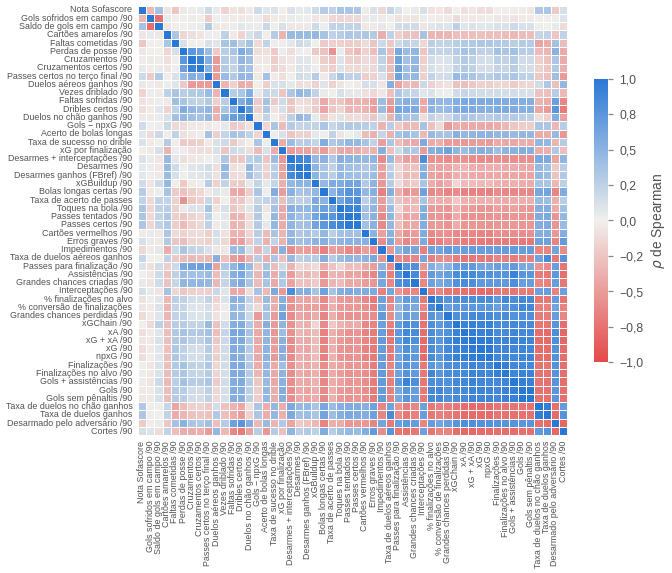

60 pares com |ρ| ≥ 0,85 entre 52 métricas de desempenho


,feature_a,feature_b,rho
1,goals_p90,npg_p90,0.992
830,passes_p90,accurate_passes_p90,0.990
380,xg_p90,npxg_p90,0.990
382,xg_p90,xg_xa_p90,0.970
424,npxg_p90,xg_xa_p90,0.967
465,xa_p90,xg_xa_p90,0.961
1290,ground_duels_won_pct,duels_won_pct,0.941
198,shots_p90,shots_on_target_p90,0.940
1173,tackles_p90,tackles_won_p90,0.939
512,xg_xa_p90,xg_chain_p90,0.932


In [11]:
perf = perf_all.loc[base.index]
perf_cols = [c for c in fc.by_role("feature") if fc.CATALOG[c].group in
             ("Ofensivo", "Criação e posse", "Defensivo", "Disciplina", "Avaliação agregada")]
rho = perf[perf_cols].corr(method="spearman")
dist = 1 - rho.abs()
order = hierarchy.leaves_list(hierarchy.linkage(squareform(dist.to_numpy(), checks=False), method="average"))
rho_ord = rho.iloc[order, order]
labels = {c: fc.label(c) for c in perf_cols}

fig, ax = plt.subplots(figsize=pl.figsize(17))
sns.heatmap(rho_ord, cmap=pl.DIVERGING, vmin=-1, vmax=1, center=0, square=True, linewidths=0.4,
            linecolor=pl.SURFACE, cbar_kws={"label": "$\\rho$ de Spearman", "shrink": 0.5}, ax=ax,
            xticklabels=[labels[c] for c in rho_ord.columns], yticklabels=[labels[c] for c in rho_ord.index])
ax.tick_params(axis="both", labelsize=5.8, length=0)
ax.collections[0].colorbar.ax.yaxis.set_major_formatter(pl.br_formatter(1))
ax.grid(False)
FIG.save(fig, "fig03_correlacao_features_desempenho",
         "Correlação de Spearman entre as métricas de desempenho em T, ordenadas por agrupamento hierárquico",
         note="Distância 1 − |ρ|, ligação média. Blocos escuros indicam multicolinearidade.")
plt.show()

pairs = (rho.where(np.triu(np.ones(rho.shape, dtype=bool), 1)).stack().rename("rho").reset_index()
         .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
high = pairs[pairs["rho"].abs() >= 0.85].sort_values("rho", key=np.abs, ascending=False)
save_csv(high, "tab07_pares_alta_correlacao", index=False)
print(f"{len(high)} pares com |ρ| ≥ 0,85 entre {len(perf_cols)} métricas de desempenho")
high.round(3)

### 5.1 Encolhimento empírico-bayesiano das taxas

Com poucos minutos, uma taxa por 90 é dominada pelo acaso: um gol em 120 minutos vale 0,75 gol/90. Por
isso cada taxa e cada eficiência é **encolhida** para a média da posição na temporada, com peso que cresce
com a exposição do atleta (`features.shrink_*`):

| Tipo de métrica | Modelo | Estimativa a posteriori |
|---|---|---|
| Contagens por 90 (gols, passes, desarmes...) | Gamma–Poisson (Clayton e Kaldor, 1987; Marshall, 1991) | $(\alpha + c)/(\beta + e)$, com $e$ = minutos/90 |
| Percentuais (acerto de passe, duelos, dribles) | Beta–binomial | $(s + \kappa\bar p)/(n + \kappa)$ |
| Nota e métricas com sinal (saldo em campo, gols − npxG) | normal–normal | $\mu + B(x - \mu)$, $B = \tau^2/(\tau^2 + \sigma^2/w)$ |

As distribuições a priori são estimadas por momentos no corte transversal de cada temporada × posição,
com os atletas de pelo menos 90 minutos, **sem nenhum alvo**. As versões cruas ficam no painel
(`*_raw`) para a comparação do notebook 04.

**Validação externa.** Uma taxa menos ruidosa deve se repetir mais de um ano para o outro. A tabela
compara o $\rho$ de Spearman entre $T-1$ e $T$ do mesmo atleta, nas versões crua e encolhida.

Pares T−1→T do mesmo atleta: 10,934 | ganho mediano de ρ: +0.111 | métricas mais estáveis após o encolhimento: 50 de 52


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/03_preprocessing/fig07_estabilidade_encolhimento.png


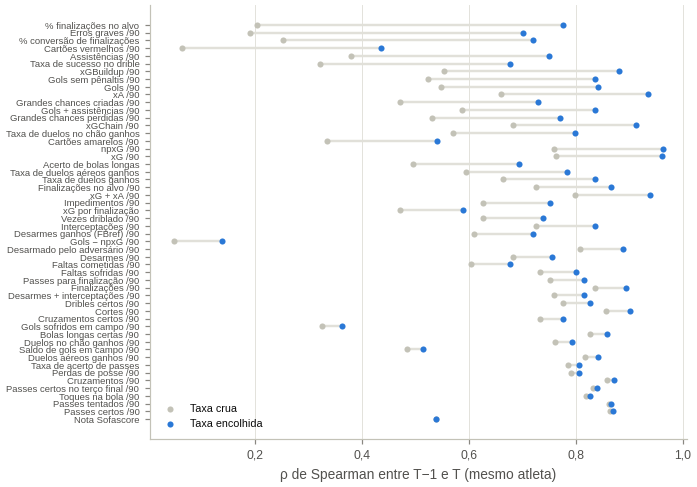

In [12]:
stab_src = ps[["season", "fbref_player_id", "position_group", "fb_minutes"]].join(perf_all)
stab_src = stab_src[stab_src["position_group"].isin(POS) & (stab_src["fb_minutes"] >= 90)]
prev = stab_src.assign(season=stab_src["season"].map(lambda s: Season(s).offset(1).code))
pairs_tt = stab_src.merge(prev, on=["season", "fbref_player_id"], suffixes=("", "_prev"))
stab = pd.DataFrame([{
    "variavel": fc.label(f), "grupo": fc.CATALOG[f].group,
    "rho_cru": pairs_tt[f"{f}_raw"].corr(pairs_tt[f"{f}_raw_prev"], method="spearman"),
    "rho_encolhido": pairs_tt[f].corr(pairs_tt[f"{f}_prev"], method="spearman"),
} for f in ft.SHRUNK_FEATURES]).assign(ganho=lambda d: d["rho_encolhido"] - d["rho_cru"]).sort_values("ganho")
save_csv(stab, "tab13_estabilidade_encolhimento", index=False)
print(f"Pares T−1→T do mesmo atleta: {len(pairs_tt):,} | ganho mediano de ρ: {stab['ganho'].median():+.3f} | "
      f"métricas mais estáveis após o encolhimento: {(stab['ganho'] > 0.005).sum()} de {len(stab)}")

fig, ax = plt.subplots(figsize=pl.figsize(13))
y = np.arange(len(stab))
ax.hlines(y, stab["rho_cru"], stab["rho_encolhido"], color=pl.GRID, linewidth=1.6)
ax.scatter(stab["rho_cru"], y, color=pl.NEUTRAL, s=16, label="Taxa crua", zorder=3)
ax.scatter(stab["rho_encolhido"], y, color=pl.BLUE, s=16, label="Taxa encolhida", zorder=3)
ax.set_yticks(y, stab["variavel"], fontsize=6.2)
ax.set_xlabel("ρ de Spearman entre T−1 e T (mesmo atleta)")
ax.xaxis.set_major_formatter(pl.br_formatter(1))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", fontsize=7)
FIG.save(fig, "fig07_estabilidade_encolhimento",
         "Estabilidade de um ano para o outro das métricas de desempenho, taxa crua versus encolhida",
         note="Jogadores de linha com ≥ 90 minutos nas duas temporadas consecutivas. Encolhimento empírico-bayesiano "
              "por temporada × posição; nenhuma variável-alvo é usada.")
plt.show()

**Leitura.** O vetor de desempenho tem **52 métricas** em cinco grupos (ofensivo, criação e posse,
defensivo, disciplina e avaliação agregada). Os nove itens tático-técnicos da especificação têm
correspondente direto ou *proxy*. A exceção são convocação para a seleção e reputação
internacional, que não foram coletadas.

O mapa de correlação (Figura 3) mostra blocos nítidos de redundância:
- volume de posse (passes, passes certos, toques);
- finalização (finalizações, xG, npxG, xG + xA);
- gols (gols, gols sem pênalti, conversão);
- ação defensiva (desarmes, desarmes ganhos, desarmes + interceptações);
- criação (xA, passes-chave, grandes chances).

**17 pares têm $|\rho| \ge 0{,}85$**, e chegam a 0,99 em passes × passes certos e xG × npxG. A
multicolinearidade não prejudica as árvores, mas torna instáveis os coeficientes do OLS. Isso
justifica empiricamente o Ridge como *baseline* linear (especificação, §6.5) e recomenda, para o
OLS, manter um representante por bloco (tabela `tab07_pares_alta_correlacao.csv`). Há também um
bloco negativo esperado: ações ofensivas se correlacionam negativamente com cortes, duelos aéreos
e interceptações, o que reflete a especialização posicional e justifica a segmentação por posição.

## 6. Defasagens e *momentum*

Há dois tipos de defasagem:

1. **Valor de mercado.** $V_{T-1}$ e $V_{T-2}$ vêm do histórico completo do Transfermarkt. Eles
   existem mesmo quando o atleta não atuava nas Big Five em $T-1$, o que permite medir o
   *momentum*, isto é, os log-retornos $\ln(V_T/V_{T-1})$ e $\ln(V_T/V_{T-2})$.
2. **Desempenho em $T-1$.** Dez métricas-chave do mesmo atleta, disponíveis apenas se ele jogou
   nas Big Five em $T-1$ (inclusive em 2018/19, coletada para este fim). Somam-se as variações de
   participação nos minutos e de nota entre $T-1$ e $T$.

A figura testa, de forma exploratória, se a valorização passada antecipa a futura (*momentum*) ou
se há reversão à média, separadamente por faixa etária.

,% preenchido
value_lag1,96.400
log_return_lag1,96.400
value_lag2,91.400
log_return_lag2,91.400
lag1_minutes,72.500
lag1_minutes_share_pct,72.400
lag1_sofascore_rating,72.000
lag1_goals_assists_p90,72.500
lag1_xg_xa_p90,72.100
lag1_key_passes_p90,72.200


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/03_preprocessing/fig04_momentum.png


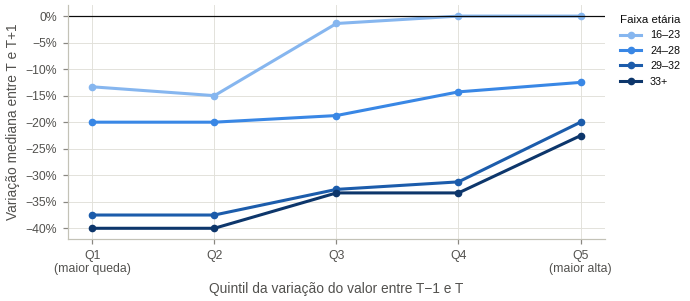

In [13]:
vlags = ft.value_lags(base, mv, max_staleness_days=cfg.value_max_staleness_days)
plags = lags_all.loc[base.index]
cover = pd.concat([vlags, plags], axis=1).notna().mean().mul(100).rename("% preenchido")
save_csv(cover.to_frame(), "tab08_cobertura_defasagens")
display(cover.round(1).to_frame())

mom = diag[["age_band", "log_return_T1"]].assign(past=vlags["log_return_lag1"]).dropna()
mom["quintil"] = pd.qcut(mom["past"], 5, labels=["Q1\n(maior queda)", "Q2", "Q3", "Q4", "Q5\n(maior alta)"])
curve = mom.groupby(["age_band", "quintil"], observed=True)["log_return_T1"].median().unstack("age_band")
save_csv(curve, "tab09_momentum_quintis")

fig, ax = plt.subplots(figsize=pl.figsize(7))
for color, band in zip(pl.AGE_BAND_COLORS, BANDS):
    ax.plot(range(5), np.expm1(curve[band]) * 100, marker="o", markersize=4, color=color, label=band)
ax.axhline(0, color=pl.INK, linewidth=0.8)
ax.set_xticks(range(5), curve.index)
ax.yaxis.set_major_formatter(pl.pct_formatter(0))
ax.set_xlabel("Quintil da variação do valor entre T−1 e T")
ax.set_ylabel("Variação mediana entre T e T+1")
ax.legend(title="Faixa etária", fontsize=7, title_fontsize=7.5, loc="upper left", bbox_to_anchor=(1.01, 1))
FIG.save(fig, "fig04_momentum",
         "Variação mediana do valor entre T e T+1 segundo o quintil da variação passada, por faixa etária",
         note="Variação mediana = exp(mediana do log-retorno) − 1. Quintis calculados sobre a amostra inteira.")
plt.show()

**Leitura.** As defasagens de valor têm cobertura alta: 96,5% para $V_{T-1}$ e 91,4% para
$V_{T-2}$, porque o histórico do Transfermarkt acompanha o atleta fora das Big Five. As de
desempenho cobrem **72,6%**. Os 27,4% restantes são atletas que não jogaram nas Big Five em $T-1$
(recém-promovidos, vindos de outras ligas ou da base). Para eles, `has_big5_lag1 = 0` e os ausentes
serão imputados dentro de cada dobra.

**Há *momentum* no valor de mercado** (Figura 4). Para atletas de até 32 anos, a variação mediana
entre $T$ e $T+1$ cresce de forma monotônica com o quintil da variação entre $T-1$ e $T$:
- 16–23 anos: de −14% para +14%;
- 24–28 anos: de −20% para 0%;
- 29–32 anos: de −38% para −20%.

Só os veteranos (33+) não mostram o padrão. A persistência das revisões é compatível com o viés de
**ancoragem e ajuste** atribuído ao processo de avaliação do Transfermarkt (Tversky e Kahneman,
1974; Herm et al., 2014). Os avaliadores corrigem o valor em etapas sucessivas, em vez de uma
única revisão. Para o modelo, `log_return_lag1` deve figurar entre as variáveis mais informativas.
Para o artigo, isso dá uma leitura econômica direta: parte da valorização futura é previsível pela
própria dinâmica de revisão da plataforma.

### 6.1 Dinâmica das reavaliações do Transfermarkt

O *momentum* anual resume a trajetória do valor numa única variação. Como o Transfermarkt revisa
os valores em etapas, a **forma** dessa trajetória até $T$ também é informativa:
- variação nos últimos seis meses;
- tamanho e idade da última revisão;
- número de revisões, para cima e para baixo, em 12 e 24 meses;
- volatilidade das revisões;
- distância ao pico histórico do atleta.

Todas usam apenas avaliações publicadas até a data-âncora de $T$.

In [14]:
mkt = ft.market_history(base, mv)
mkt_rho = pd.DataFrame({
    "% preenchido": mkt.notna().mean() * 100,
    "rho_log_retorno_T1": [mkt[c].corr(diag["log_return_T1"], method="spearman") for c in mkt.columns],
    "rho_log_retorno_T2": [mkt[c].corr(diag["log_return_T2"], method="spearman") for c in mkt.columns],
}).rename(index=fc.label)
save_csv(mkt_rho, "tab08b_dinamica_mercado")
mkt_rho.round(3)

,% preenchido,rho_log_retorno_T1,rho_log_retorno_T2
Variação do valor em 6 meses,99.214,0.279,0.275
Última revisão de valor,100.000,0.251,0.261
Dias desde a última revisão,99.360,0.021,0.016
Nº de revisões (12 meses),100.000,0.085,0.091
Revisões para cima (24 meses),100.000,0.250,0.270
Revisões para baixo (24 meses),100.000,-0.254,-0.282
Volatilidade das revisões (24 meses),98.974,0.216,0.261
Distância ao pico de valor,100.000,0.314,0.345


### 6.2 Valor justo e gap de avaliação (*buy-low*)

O modelo de negócio do estudo procura atletas **subavaliados**. Isso se operacionaliza com um
**valor justo** em $T$: a previsão de $\ln V_T$ a partir do desempenho, da idade, da posição e do
contexto em $T$, estimada por XGBoost **dentro de cada temporada**. O **gap de avaliação** é
$\ln V_T$ menos o valor justo; um gap negativo indica um atleta mais barato do que o desempenho
sugere.

Não há antecipação de informação. Todos os $V_T$ de uma temporada são públicos na data-âncora, e
a estimação por validação cruzada em cinco partes garante que o gap de cada atleta venha de um
modelo que não o viu. Ficam fora dos insumos as variáveis construídas a partir do próprio $V_T$.

Valor justo (nowcasting de ln V_T, fora da dobra): R² = 0.787


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/03_preprocessing/fig04b_gap_avaliacao.png


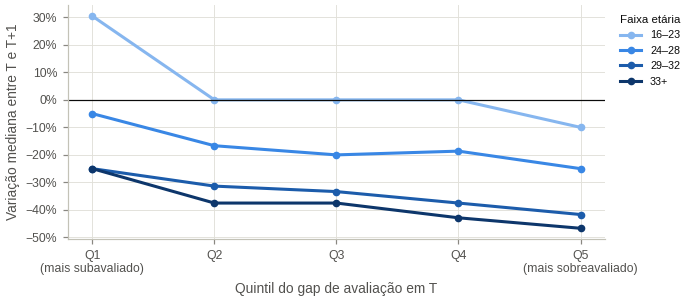

In [15]:
pre = pd.concat([base[["season", "league", "position_group"]].assign(value_T=base["tm_value_T"]),
                 demo.drop(columns="confederation"), contracts[["tenure_years_T", "is_on_loan_T"]], market.drop(columns="value_T"), context, perf,
                 vlags[["log_return_lag1", "log_return_lag2"]], plags, mkt], axis=1)
gap = ft.valuation_gap(pre, [c for c in fc.by_role("feature") if c in pre.columns])
logv = np.log(base["tm_value_T"])
nowcast_r2 = 1 - ((logv - gap["fair_log_value_T"]) ** 2).sum() / ((logv - logv.mean()) ** 2).sum()
print(f"Valor justo (nowcasting de ln V_T, fora da dobra): R² = {nowcast_r2:.3f}")

q = diag[["age_band", "log_return_T1"]].assign(gap=gap["value_gap_T"]).dropna()
q["quintil"] = pd.qcut(q["gap"], 5, labels=["Q1\n(mais subavaliado)", "Q2", "Q3", "Q4", "Q5\n(mais sobreavaliado)"])
gap_curve = q.groupby(["age_band", "quintil"], observed=True)["log_return_T1"].median().unstack("age_band")
save_csv(gap_curve, "tab09b_gap_quintis")

fig, ax = plt.subplots(figsize=pl.figsize(7))
for color, band in zip(pl.AGE_BAND_COLORS, BANDS):
    ax.plot(range(5), np.expm1(gap_curve[band]) * 100, marker="o", markersize=4, color=color, label=band)
ax.axhline(0, color=pl.INK, linewidth=0.8)
ax.set_xticks(range(5), gap_curve.index)
ax.yaxis.set_major_formatter(pl.pct_formatter(0))
ax.set_xlabel("Quintil do gap de avaliação em T")
ax.set_ylabel("Variação mediana entre T e T+1")
ax.legend(title="Faixa etária", fontsize=7, title_fontsize=7.5, loc="upper left", bbox_to_anchor=(1.01, 1))
FIG.save(fig, "fig04b_gap_avaliacao",
         "Variação mediana do valor entre T e T+1 segundo o quintil do gap de avaliação em T, por faixa etária",
         note="Gap = ln(V_T) − valor justo estimado pelo desempenho em T (corte transversal, validação cruzada).")
plt.show()

**Leitura.**

*Dinâmica de reavaliações.* As oito variáveis de histórico se associam de forma consistente à
valorização seguinte. Em $T+1$:
- distância ao pico: $\rho \approx 0{,}35$;
- variação nos últimos seis meses: $\rho \approx 0{,}29$;
- revisões para baixo em 24 meses: $\rho \approx -0{,}29$;
- tamanho da última revisão: $\rho \approx 0{,}27$.

Isso reforça a leitura de **ancoragem e ajuste**: uma revisão recente para cima tende a ser
seguida de outras na mesma direção.

*Valor justo e gap.* O valor justo explica cerca de **75% da variância de $\ln V_T$** fora da
dobra. É o patamar de $R^2$ da literatura de *nowcasting* (Müller et al., 2017) e um contraste
útil para o texto: estimar o nível do valor é muito mais fácil que prever sua variação. Em todas as
faixas etárias, os atletas do quintil mais subavaliado se valorizam mais (ou se desvalorizam menos)
que os do quintil mais sobreavaliado (Figura 4b). Essa é a evidência empírica direta da premissa
*buy-low* do estudo: o mercado corrige parcialmente o desalinhamento entre preço e desempenho.

## 7. Variáveis-alvo

Para cada horizonte $k \in \{1, 2\}$ gravam-se três versões do alvo: $\Delta V$ (€), $\Delta V\%$ e
o log-retorno $\ln(V_{T+k}/V_T)$. Pelo diagnóstico do notebook 02 (assimetria de 19,5 em
$\Delta V\%$ contra 1,0 no log-retorno), o **log-retorno é o alvo de treino recomendado**. As
previsões são reconvertidas para $\Delta V\% = e^{\hat{y}} - 1$ na avaliação e na interpretação.
Atletas sem $V_{T+k}$ observado não são imputados. Ficam marcados (`has_target_Tk`) e saem do
treino daquele horizonte, por causa do viés de sobrevivência discutido no notebook 02.

In [16]:
targets = base[["delta_v_T1", "delta_v_pct_T1", "log_return_T1", "delta_v_T2", "delta_v_pct_T2", "log_return_T2"]].copy()
targets["has_target_T1"] = base["log_return_T1"].notna().astype(float)
targets["has_target_T2"] = base["log_return_T2"].notna().astype(float)
avail = base.assign(t1=targets["has_target_T1"], t2=targets["has_target_T2"]).groupby("season")[["t1", "t2"]].sum()
avail.index = SEASON_LABELS
avail.columns = ["com alvo T+1", "com alvo T+2"]
display(avail.astype(int))

,com alvo T+1,com alvo T+2
2018/19,1849,1793
2019/20,1884,1833
2020/21,1967,1890
2021/22,1946,1914
2022/23,1959,1905
2023/24,1926,1879
2024/25,1952,0


## 8. Estrutura temporal: validação por janela expandida

As dobras seguem a especificação (§6.3). No horizonte $T+1$, o modelo treina em $[T_1, \dots, T_k]$
e é testado em $T_{k+1}$. No horizonte $T+2$, a temporada $T_{k+1}$ é **purgada**: o alvo de uma
observação de treino em $T_{k+1}$ seria medido em $T_{k+3}$, depois da data em que as *features* do
teste ficam disponíveis. Isso resulta em quatro dobras para $T+1$ e três para $T+2$.

,horizonte,dobra,treino,purgada,teste,n_treino,n_teste
0,T+1,1,2018/19,—,2019/20,1849,1884
1,T+1,2,"2018/19, 2019/20",—,2020/21,3733,1967
2,T+1,3,"2018/19, 2019/20, 2020/21",—,2021/22,5700,1946
3,T+1,4,"2018/19, 2019/20, 2020/21, 2021/22",—,2022/23,7646,1959
4,T+1,5,"2018/19, 2019/20, 2020/21, 2021/22, 2022/23",—,2023/24,9605,1926
5,T+1,6,"2018/19, 2019/20, 2020/21, 2021/22, 2022/23, 2...",—,2024/25,11531,1952
6,T+2,1,2018/19,2019/20,2020/21,1793,1890
7,T+2,2,"2018/19, 2019/20",2020/21,2021/22,3626,1914
8,T+2,3,"2018/19, 2019/20, 2020/21",2021/22,2022/23,5516,1905
9,T+2,4,"2018/19, 2019/20, 2020/21, 2021/22",2022/23,2023/24,7430,1879


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/03_preprocessing/fig05_janela_expandida.png


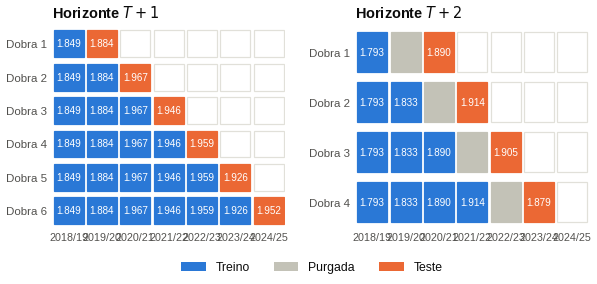

In [17]:
folds = {k: expanding_window_folds(cfg.target_seasons(k), horizon=k) for k in (1, 2)}
for k, fl in folds.items():  # a última dobra de cada horizonte é o teste final declarado
    assert fl[-1].test == cfg.holdout_seasons[k], (k, fl[-1].test)
n_t = {k: base.groupby("season")[f"log_return_T{k}"].count() for k in (1, 2)}
rows = []
for k, fl in folds.items():
    for i, f in enumerate(fl, 1):
        rows.append({"horizonte": f"T+{k}", "dobra": i,
                     "treino": ", ".join(sp.season_label(s) for s in f.train),
                     "purgada": ", ".join(sp.season_label(s) for s in f.purged) or "—",
                     "teste": sp.season_label(f.test),
                     "n_treino": int(n_t[k].loc[list(f.train)].sum()), "n_teste": int(n_t[k].loc[f.test])})
fold_tab = pd.DataFrame(rows)
save_csv(fold_tab, "tab10_dobras_janela_expandida", index=False)
display(fold_tab)

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(6), gridspec_kw={"wspace": 0.3})
role_color = {"Treino": pl.BLUE, "Purgada": pl.NEUTRAL, "Teste": pl.ORANGE}
for ax, (k, fl) in zip(axes, folds.items()):
    for i, f in enumerate(fl):
        for j, s in enumerate(SEASONS):
            role = "Treino" if s in f.train else "Purgada" if s in f.purged else "Teste" if s == f.test else None
            face = role_color.get(role, pl.SURFACE)
            ax.add_patch(plt.Rectangle((j + 0.05, i + 0.1), 0.9, 0.8, facecolor=face,
                                       edgecolor=pl.GRID if role is None else face, linewidth=0.8))
            if role in ("Treino", "Teste"):
                ax.text(j + 0.5, i + 0.5, pl.br(n_t[k].loc[s], 0), ha="center", va="center", fontsize=6.5,
                        color=pl.SURFACE)
    ax.set_xlim(0, len(SEASONS))
    ax.set_ylim(len(fl), 0)
    ax.set_xticks(np.arange(len(SEASONS)) + 0.5, SEASON_LABELS, fontsize=7)
    ax.set_yticks(np.arange(len(fl)) + 0.5, [f"Dobra {i + 1}" for i in range(len(fl))], fontsize=7.5)
    ax.tick_params(length=0)
    ax.grid(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.set_title(f"Horizonte $T+{k}$")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in role_color.values()]
fig.legend(handles, list(role_color), loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=3)
FIG.save(fig, "fig05_janela_expandida",
         "Esquema da validação por janela expandida nos horizontes T+1 e T+2",
         note="Números: observações com alvo observado em cada temporada de referência.")
plt.show()

## 9. Montagem do painel, verificações e gravação

In [18]:
meta = pd.DataFrame({
    "season": base["season"], "season_order": base["season"].map({s: i for i, s in enumerate(SEASONS)}),
    "fbref_player_id": base["fbref_player_id"], "tm_player_id": base["tm_player_id"].astype("Int64"),
    "fb_player": base["fb_player"], "fb_team": base["fb_team"], "fbref_team_id": base["fbref_team_id"],
    "league": base["league"], "position_group": base["position_group"], "age_band": base["age_band"].astype(str),
    "category": base["category"], "age_band_3x3": base["age_band_3x3"].astype(str),
    "category_3x3": base["category_3x3"], "confederation": demo["confederation"],
    "value_T": base["tm_value_T"], "value_T1": base["tm_value_T1"], "value_T2": base["tm_value_T2"],
}, index=base.index)
contract_feats = contracts[["contract_years_remaining_T", "bosman_T", "tenure_years_T", "is_on_loan_T"]]
# limite otimista do backtest por intenção de tratar: último valor publicado até T+k, sem limite de defasagem
last_obs = attach_values(base[["tm_player_id", "season"]], mv, horizons=(1, 2), max_staleness_days=100_000)
audit = contracts[["contract_method", "contract_is_estimated", "contract_expiry_T"]].assign(
    birth_date_is_estimated=base["birth_date_is_estimated"], tm_value_date_T=base["tm_value_date_T"],
    value_T1_last_obs=last_obs["tm_value_T1"].to_numpy(), value_T2_last_obs=last_obs["tm_value_T2"].to_numpy())
lag_cols = ["log_return_lag1", "log_return_lag2"]
panel = pd.concat([
    meta, demo.drop(columns="confederation"), contract_feats,
    market.drop(columns="value_T"), context, perf, vlags[lag_cols], plags, mkt, gap, targets, audit,
], axis=1).reset_index(drop=True)

# --- verificações ---------------------------------------------------------------------------
catalog_cols = set(fc.CATALOG)
undocumented = [c for c in panel.columns if c not in catalog_cols]
assert not undocumented, f"colunas sem entrada no catálogo: {undocumented}"
missing_cols = [c for c in fc.CATALOG if c not in panel.columns]
assert not missing_cols, f"catálogo prevê colunas ausentes: {missing_cols}"
assert not panel.duplicated(["season", "fbref_player_id"]).any()
assert len(panel) == len(sample_keys)
numeric, categorical = fc.by_role("feature"), fc.by_role("categorical")
# fontes opcionais sem cobertura (ex.: ClubElo fora do ar) saem do vetor, com o motivo registrado
opt_cov = panel.groupby("season")[list(fc.OPTIONAL_FEATURES)].apply(lambda d: d.notna().mean()).min()
excluded = {c: f"cobertura mínima por temporada de {opt_cov[c] * 100:.0f}% (< 90%)" for c in fc.OPTIONAL_FEATURES
            if opt_cov[c] < 0.9}
numeric = [c for c in numeric if c not in excluded]
print("Fora do vetor por cobertura:", excluded or "nenhuma")
forbidden = (set(fc.by_role("target")) | set(fc.by_role("audit")) | set(fc.by_role("lookahead"))
             | {"value_T1", "value_T2", "has_target_T1", "has_target_T2"})
assert not forbidden & set(numeric), "alvo ou auditoria no vetor explicativo"
# nenhuma avaliação usada em T é posterior à âncora de T
anchor = panel["season"].map(lambda s: pd.Timestamp(Season(s).end_anchor))
assert (pd.to_datetime(panel["tm_value_date_T"]) <= anchor).all()
assert not np.isinf(panel[numeric].to_numpy(dtype=float)).any(), "valor infinito em feature"
print(f"Painel: {len(panel):,} linhas x {panel.shape[1]} colunas | {len(numeric)} features numéricas, "
      f"{len(categorical)} categóricas, {len(fc.by_role('target'))} alvos")

Fora do vetor por cobertura: {'club_elo_T': 'cobertura mínima por temporada de 0% (< 90%)', 'club_elo_change_T': 'cobertura mínima por temporada de 0% (< 90%)', 'tenure_years_T': 'cobertura mínima por temporada de 80% (< 90%)', 'is_on_loan_T': 'cobertura mínima por temporada de 80% (< 90%)'}


Painel: 13,748 linhas x 198 colunas | 108 features numéricas, 7 categóricas, 6 alvos


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/03_preprocessing/fig06_ausentes_features.png


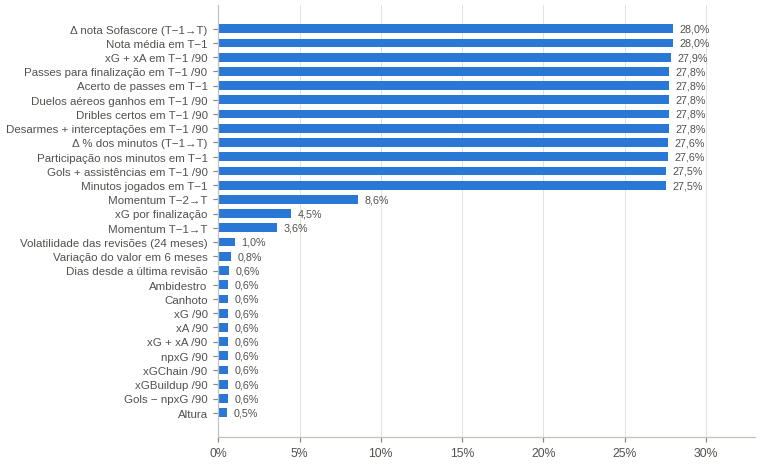

55 de 108 features têm algum ausente; 13 acima de 5%


In [19]:
miss = panel[numeric].isna().mean().mul(100)
miss_tab = (pd.DataFrame({"pct_ausente": miss, "grupo": [fc.CATALOG[c].group for c in miss.index]})
            .sort_values("pct_ausente", ascending=False))
save_csv(miss_tab, "tab11_ausentes_features")
show = miss_tab[miss_tab["pct_ausente"] > 0.5]

fig, ax = plt.subplots(figsize=pl.figsize(max(4.5, 0.42 * len(show) + 1.2)))
ax.barh(range(len(show)), show["pct_ausente"], color=pl.BLUE, height=0.62)
ax.set_yticks(range(len(show)), [fc.label(c) for c in show.index], fontsize=7.5)
ax.invert_yaxis()
for i, v in enumerate(show["pct_ausente"]):
    ax.text(v + 0.4, i, pl.br_pct(v, 1), va="center", fontsize=7, color=pl.INK_SECONDARY)
ax.xaxis.set_major_formatter(pl.pct_formatter(0))
ax.set_xlim(0, show["pct_ausente"].max() * 1.18)
ax.grid(axis="y", visible=False)
FIG.save(fig, "fig06_ausentes_features",
         "Features com mais de 0,5% de valores ausentes no painel de modelagem",
         note="Ausentes são imputados dentro de cada dobra no notebook 04 (mediana por posição, só com o treino).")
plt.show()
print(f"{(miss > 0).sum()} de {len(numeric)} features têm algum ausente; {(miss > 5).sum()} acima de 5%")

In [20]:
out_path = paths.processed / "train_test_lags.parquet"
dictionary = fc.dictionary_frame(list(panel.columns))
save_table(panel, out_path, source="notebook 03: painel jogador–temporada (features em T, alvos em T+1/T+2)",
           description=dict(zip(dictionary["variavel"], dictionary["descricao"])))
dictionary.to_csv(TABLES / "tab12_dicionario_variaveis.csv", index=False, encoding="utf-8-sig")

feature_sets = {
    "numeric_features": numeric,
    "categorical_features": categorical,
    "feature_groups": {g: [c for c in numeric if fc.CATALOG[c].group == g]
                       for g in dict.fromkeys(fc.CATALOG[c].group for c in numeric)},
    "targets": {"T1": {"log_return": "log_return_T1", "delta_v_pct": "delta_v_pct_T1", "delta_v": "delta_v_T1"},
                "T2": {"log_return": "log_return_T2", "delta_v_pct": "delta_v_pct_T2", "delta_v": "delta_v_T2"}},
    "primary_target": {"T1": "log_return_T1", "T2": "log_return_T2"},
    "target_available": {"T1": "has_target_T1", "T2": "has_target_T2"},
    "lookahead_features": fc.by_role("lookahead"),
    "excluded_features": excluded,
    "raw_twins": {c: f"{c}_raw" for c in ft.SHRUNK_FEATURES if c in numeric},
    "holdout_seasons": {f"T{k}": v for k, v in cfg.holdout_seasons.items()},
    "value_cutoff": cfg.value_cutoff.isoformat(),
    "audit_columns": fc.by_role("audit"),
    "segmentation": {"category": "category", "age_band": "age_band", "position_group": "position_group",
                     "category_3x3": "category_3x3", "age_band_3x3": "age_band_3x3"},
    "folds": {f"T{k}": [{"train": list(f.train), "purged": list(f.purged), "test": f.test} for f in fl]
              for k, fl in folds.items()},
}
(paths.processed / "feature_sets.json").write_text(json.dumps(feature_sets, ensure_ascii=False, indent=2), encoding="utf-8")
FIG.write_index()
print("gravado:", out_path, "e feature_sets.json")
pd.Series({g: len(v) for g, v in feature_sets["feature_groups"].items()}, name="n_features").to_frame()

I               io | tabela gravada  path=/home/alvaro/Documents/TCC/football-analytics/data/processed/train_test_lags.parquet rows=13748 cols=198


gravado: /home/alvaro/Documents/TCC/football-analytics/data/processed/train_test_lags.parquet e feature_sets.json


,n_features
Demográfico,12
Mercado,5
Contexto,8
Volume,6
Ofensivo,16
Criação e posse,18
Defensivo,14
Disciplina,3
Avaliação agregada,1
Defasagem,15


## 10. Síntese para o artigo

**Painel de modelagem** (`data/processed/train_test_lags.parquet`)
- 9.810 observações jogador–temporada (2019/20–2023/24), 4.084 atletas e 123 colunas.
- **105 *features* numéricas** e 5 categóricas, distribuídas em: demografia (12), contrato (2),
  mercado e contexto (8), dinâmica de mercado (8), valor justo (2), volume (6), ofensivo (16), criação e posse (18), defensivo (14),
  disciplina (3), avaliação agregada (1) e defasagens (15).
- Duas variáveis contratuais de sensibilidade (tempo restante e status Bosman).
- Seis alvos: $\Delta V$, $\Delta V\%$ e log-retorno em $T+1$ e $T+2$. O alvo de treino
  recomendado é o log-retorno.
- O dicionário de dados completo está em `tab12_dicionario_variaveis.csv`.

**Decisões metodológicas**
1. **Agregação.** Transferidos dentro das Big Five têm as contagens somadas e as taxas recalculadas.
   As taxas por 90 minutos usam os minutos da própria fonte.
2. **Contrato.** O contrato vigente em $T$ foi reconstruído: 46,5% observado e 53,5% estimado, com
   erro médio de 0,99 ano. Por depender de eventos posteriores a $T$, fica restrito a análise de
   robustez.
3. **Defasagens.** O *momentum* do valor de mercado é monotônico até 32 anos, e as defasagens de
   desempenho cobrem 72,6% da amostra.
4. **Validação.** Janela expandida com 4 dobras em $T+1$ e 3 dobras com purga de uma temporada em
   $T+2$ (Figura 5). O treino vai de 1.872 a 7.705 observações em $T+1$ e de 1.822 a 5.599 em $T+2$.
5. **Imputação e escalonamento.** Ficam para o notebook 04, dentro de cada dobra. Pela
   especificação, a imputação usa a mediana por posição e o escalonamento é robusto por categoria.

**Recomendações para o notebook 04**
- Treinar no log-retorno e avaliar em $\Delta V\%$ reconvertido (RMSE, MAE, $R^2$), em nível global
  e por categoria.
- No OLS, usar um representante por bloco de alta correlação. O Ridge e as árvores recebem o vetor
  completo.
- Rodar um modelo de robustez com `contract_years_remaining_T` e `bosman_T`, explicitamente
  rotulado como sujeito a *look-ahead*.
- Nas categorias de veteranos (C10–C12, cerca de 40–90 observações por temporada), avaliar um
  número mínimo de observações de treino ou um modelo global com a categoria como *feature*.